# EDA 1 — Labels, modality and demographics

This notebook looks at the two small CSV files of the competition, without the images:

- `train.csv`: one row per series (3D scan) with age, sex, modality and the 14 labels
- `train_localizers.csv`: the point where each aneurysm is marked on the image

Questions:
1. How many series have an aneurysm, and in which locations?
2. Are the labels consistent?
3. Does the positive rate change with modality, age or sex?
4. What do the localizer points look like?

In [1]:
import ast
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import ID_COL, LOCATION_COLS, TARGET_COL

RAW = ROOT / "data" / "raw"
df = pd.read_csv(RAW / "train.csv")
loc = pd.read_csv(RAW / "train_localizers.csv")

# Plot style: one blue for single series, blue/orange for negative/positive
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
    "axes.edgecolor": GRAY, "axes.labelcolor": GRAY, "xtick.color": GRAY, "ytick.color": GRAY,
})

## 1. Overview

In [2]:
print("train.csv:", df.shape, "| train_localizers.csv:", loc.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate series IDs:", df[ID_COL].duplicated().sum())
df.head()

train.csv: (4348, 18) | train_localizers.csv: (2254, 4)
Missing values: 0
Duplicate series IDs: 0


,SeriesInstanceUID,PatientAge,PatientSex,Modality,Left Infraclinoid Internal Carotid Artery,Right Infraclinoid Internal Carotid Artery,Left Supraclinoid Internal Carotid Artery,Right Supraclinoid Internal Carotid Artery,Left Middle Cerebral Artery,Right Middle Cerebral Artery,Anterior Communicating Artery,Left Anterior Cerebral Artery,Right Anterior Cerebral Artery,Left Posterior Communicating Artery,Right Posterior Communicating Artery,Basilar Tip,Other Posterior Circulation,Aneurysm Present
0,1.2.826.0.1.3680043.8.498.10004044428023505108...,64,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,1.2.826.0.1.3680043.8.498.10004684224894397679...,76,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,1.2.826.0.1.3680043.8.498.10005158603912009425...,58,Male,CTA,0,0,0,0,0,0,0,0,0,0,0,0,1,1
3,1.2.826.0.1.3680043.8.498.10009383108068795488...,71,Male,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,1.2.826.0.1.3680043.8.498.10012790035410518400...,48,Female,MRA,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 2. Aneurysm Present

The main label. Half of the competition score comes from this one column.

Aneurysm Present
0    2485
1    1863 
positive rate: 42.8%


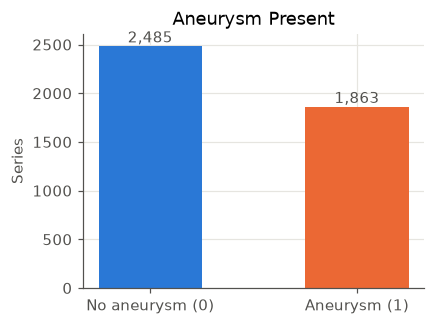

In [3]:
counts = df[TARGET_COL].value_counts().sort_index()
print(counts.to_string(), f"\npositive rate: {df[TARGET_COL].mean():.1%}")

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["No aneurysm (0)", "Aneurysm (1)"], counts.values, color=[BLUE, ORANGE], width=0.5)
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", color=GRAY)
ax.set_ylabel("Series")
ax.set_title("Aneurysm Present")
plt.show()

## 3. Locations

Number of series with an aneurysm in each of the 13 artery locations.
These are the other half of the score: each location's AUC counts equally.

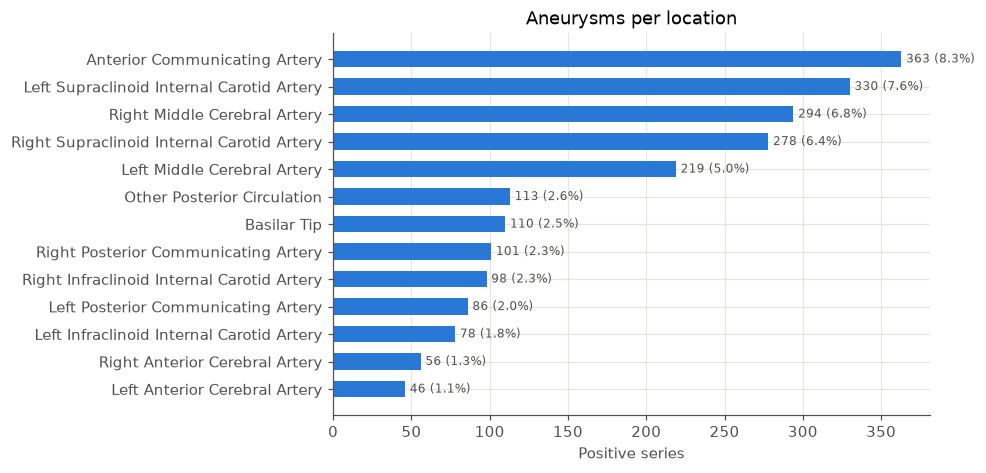

In [4]:
loc_counts = df[LOCATION_COLS].sum().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(loc_counts.index, loc_counts.values, color=BLUE, height=0.6)
for i, v in enumerate(loc_counts.values):
    ax.text(v + 3, i, f"{v} ({v / len(df):.1%})", va="center", color=GRAY, fontsize=8)
ax.set_xlabel("Positive series")
ax.set_title("Aneurysms per location")
plt.show()

## 4. Label consistency

`Aneurysm Present` should be 1 exactly when at least one location is 1.

In [5]:
any_location = (df[LOCATION_COLS].sum(axis=1) > 0).astype(int)
print("Rows where Aneurysm Present != (any location):", (any_location != df[TARGET_COL]).sum())

Rows where Aneurysm Present != (any location): 0


## 5. Series with more than one aneurysm location

1    1614
2     202
3      37
4       7
5       3


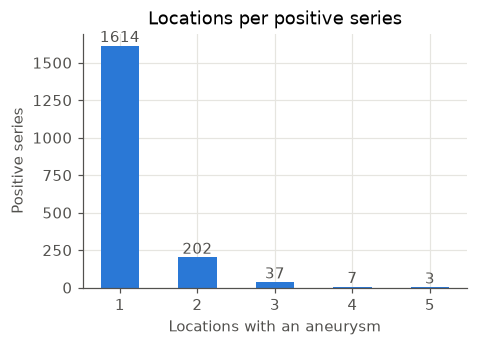

In [6]:
n_locations = df.loc[df[TARGET_COL] == 1, LOCATION_COLS].sum(axis=1)
n_counts = n_locations.value_counts().sort_index()
print(n_counts.to_string())

fig, ax = plt.subplots(figsize=(4.5, 3))
ax.bar(n_counts.index.astype(str), n_counts.values, color=BLUE, width=0.5)
for i, v in enumerate(n_counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", color=GRAY)
ax.set_xlabel("Locations with an aneurysm")
ax.set_ylabel("Positive series")
ax.set_title("Locations per positive series")
plt.show()

## 6. Modality

CTA is a CT scan with contrast; MRA, MRI T2 and MRI T1post are MR scans.

            series positive_rate
Modality                        
CTA           1808         53.8%
MRA           1252         44.3%
MRI T2         983         26.2%
MRI T1post     305         25.2%


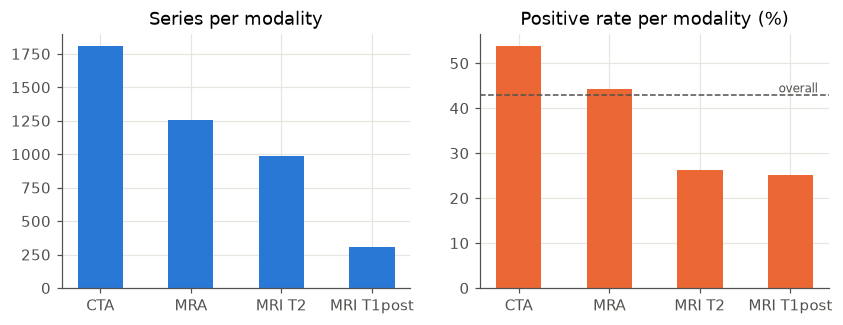

In [7]:
by_mod = df.groupby("Modality")[TARGET_COL].agg(series="size", positive_rate="mean")
by_mod = by_mod.sort_values("series", ascending=False)
print(by_mod.to_string(formatters={"positive_rate": "{:.1%}".format}))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3))
ax1.bar(by_mod.index, by_mod["series"], color=BLUE, width=0.5)
ax1.set_title("Series per modality")
ax2.bar(by_mod.index, by_mod["positive_rate"] * 100, color=ORANGE, width=0.5)
ax2.axhline(df[TARGET_COL].mean() * 100, color=GRAY, ls="--", lw=1)
ax2.text(3.3, df[TARGET_COL].mean() * 100, "overall", va="bottom", ha="right", color=GRAY, fontsize=8)
ax2.set_title("Positive rate per modality (%)")
plt.show()

## 7. Modality × location

Among the positive series of each modality, the share that has an aneurysm in each location.

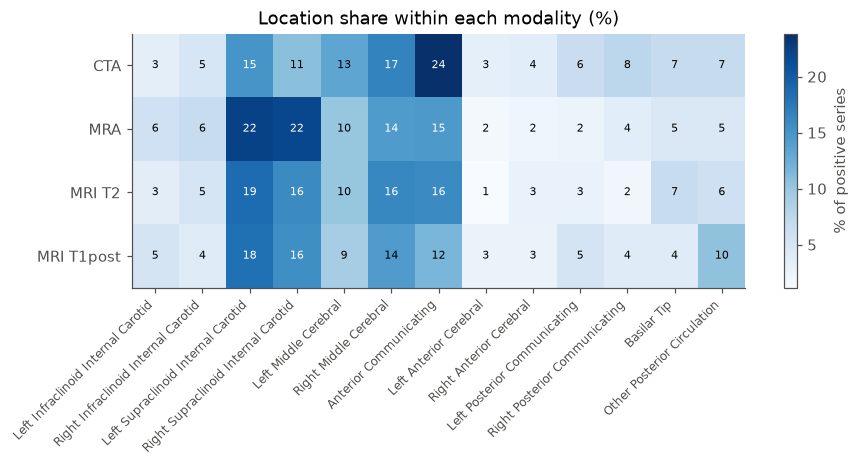

In [8]:
pos = df[df[TARGET_COL] == 1]
share = pos.groupby("Modality")[LOCATION_COLS].mean().loc[by_mod.index]

fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(share.values * 100, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(LOCATION_COLS)), [c.replace(" Artery", "") for c in LOCATION_COLS],
              rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(share)), share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        v = share.values[i, j] * 100
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v > share.values.max() * 60 else "black")
ax.grid(False)
fig.colorbar(im, ax=ax, label="% of positive series")
ax.set_title("Location share within each modality (%)")
plt.show()

## 8. Age

count    4348.0
mean       58.5
std        15.8
min        18.0
25%        48.0
50%        60.0
75%        70.0
max        89.0


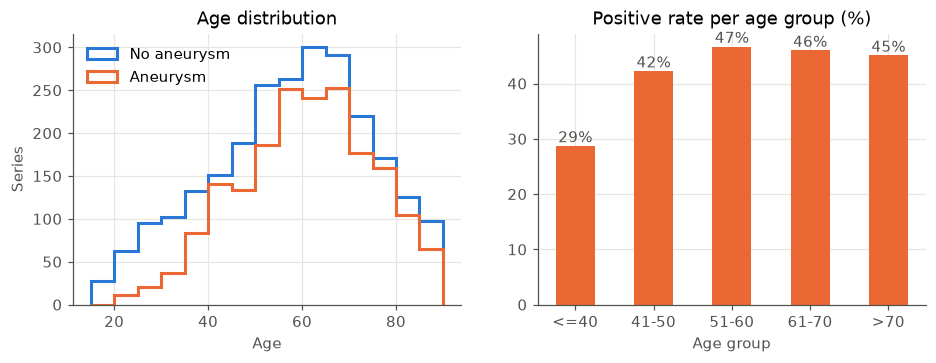

In [9]:
print(df["PatientAge"].describe().round(1).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.2))
bins = np.arange(15, 95, 5)
for label, color, name in [(0, BLUE, "No aneurysm"), (1, ORANGE, "Aneurysm")]:
    ax1.hist(df.loc[df[TARGET_COL] == label, "PatientAge"], bins=bins,
             histtype="step", lw=2, color=color, label=name)
ax1.set_xlabel("Age")
ax1.set_ylabel("Series")
ax1.legend(frameon=False)
ax1.set_title("Age distribution")

age_bins = pd.cut(df["PatientAge"], [0, 40, 50, 60, 70, 100], labels=["<=40", "41-50", "51-60", "61-70", ">70"])
rate = df.groupby(age_bins, observed=True)[TARGET_COL].mean() * 100
ax2.bar(rate.index.astype(str), rate.values, color=ORANGE, width=0.5)
for i, v in enumerate(rate.values):
    ax2.text(i, v, f"{v:.0f}%", ha="center", va="bottom", color=GRAY)
ax2.set_xlabel("Age group")
ax2.set_title("Positive rate per age group (%)")
plt.show()

## 9. Sex

            series positive_rate
PatientSex                      
Female        3005         46.8%
Male          1343         34.0%

Positive rate by sex and modality:
Modality     CTA   MRA  MRI T1post  MRI T2
PatientSex                                
Female      59.4  48.9        25.5    29.7
Male        43.3  32.8        24.7    17.2


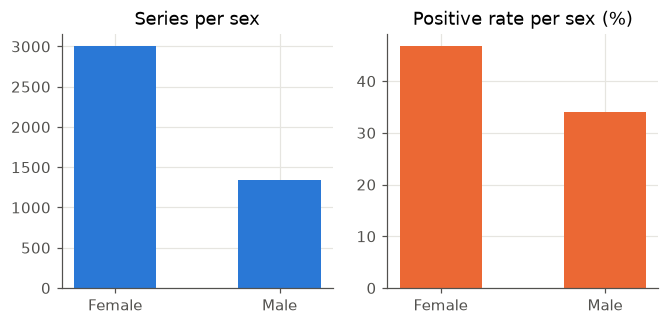

In [10]:
by_sex = df.groupby("PatientSex")[TARGET_COL].agg(series="size", positive_rate="mean")
print(by_sex.to_string(formatters={"positive_rate": "{:.1%}".format}))
print()
print("Positive rate by sex and modality:")
print((df.pivot_table(index="PatientSex", columns="Modality", values=TARGET_COL) * 100).round(1).to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7, 3))
ax1.bar(by_sex.index, by_sex["series"], color=BLUE, width=0.5)
ax1.set_title("Series per sex")
ax2.bar(by_sex.index, by_sex["positive_rate"] * 100, color=ORANGE, width=0.5)
ax2.set_title("Positive rate per sex (%)")
plt.show()

## 10. Localizers

Each row of `train_localizers.csv` marks one aneurysm on one slice:
`SOPInstanceUID` is the slice (DICOM file), `coordinates` the pixel position, `location` the artery.

In [11]:
coords = loc["coordinates"].map(ast.literal_eval)
pos_ids = set(df.loc[df[TARGET_COL] == 1, ID_COL])
loc_ids = set(loc[ID_COL])

print("Series with localizers:", len(loc_ids), "| positive series:", len(pos_ids))
print("Localizers on negative series:", len(loc_ids - pos_ids))
print("Positive series without localizer:", len(pos_ids - loc_ids))
print("Location names not in train.csv:", set(loc["location"]) - set(LOCATION_COLS))
print()
print("Coordinate keys:")
print(coords.map(lambda c: ", ".join(sorted(c))).value_counts().to_string())
print()
print("Localizer points per series:")
print(loc.groupby(ID_COL).size().value_counts().sort_index().to_string())

# Do localizer locations agree with the labels in train.csv?
loc_sets = loc.groupby(ID_COL)["location"].apply(set)
label_sets = df.set_index(ID_COL)[LOCATION_COLS].apply(lambda r: set(r.index[r == 1]), axis=1)
match = (loc_sets == label_sets.reindex(loc_sets.index))
print("\nSeries where localizer locations == train.csv locations:", f"{match.mean():.2%}")
print("Series with several points for the same location:",
      (loc.groupby(ID_COL).size() > loc.groupby(ID_COL)["location"].nunique()).sum())

Series with localizers: 1863 | positive series: 1863
Localizers on negative series: 0
Positive series without localizer: 0
Location names not in train.csv: set()

Coordinate keys:
coordinates
x, y       2108
f, x, y     146

Localizer points per series:
1    1571
2     218
3      56
4      11
5       7



Series where localizer locations == train.csv locations: 99.89%
Series with several points for the same location: 65


## 11. Findings

**Labels**
- 4,348 series, no missing values, no duplicate series.
- 1,863 series (42.8%) have an aneurysm. Classes are fairly balanced for `Aneurysm Present`.
- The 13 locations are much rarer: from 363 series (Anterior Communicating Artery, 8.3%) down to 46 (Left Anterior Cerebral Artery, 1.1%).
- Labels are consistent: `Aneurysm Present` is 1 exactly when at least one location is 1.
- 249 positive series (13%) have aneurysms in 2 or more locations, so the location task is multi-label.

**Modality, age, sex**
- CTA 1,808 · MRA 1,252 · MRI T2 983 · MRI T1post 305.
- Positive rate depends strongly on modality: CTA 53.8%, MRA 44.3%, MRI T2 26.2%, MRI T1post 25.2%.
- Women are 69% of the series and have a higher positive rate (46.8% vs 34.0%).
- Patients under 40 have a lower positive rate (29% vs about 45% for older groups); after 50 the rate is flat.

**Localizers**
- Every positive series has at least one localizer point, and no negative series has one.
- Localizer locations match the `train.csv` labels in almost all series.
- 146 points have an extra `f` key: the frame index, used for the single-file (multi-frame) series.
- 65 series have several points for the same location.

**What this means for the next steps**
- Modality, sex and age carry real signal, so B1 (a model on these columns only) should score clearly above 0.5.
  This reflects how the dataset was collected, not biology, so a good image model must do better than this.
- Rare locations (about 46–100 positives) give only 10–20 positives per CV fold, so their AUCs will be noisy.
  The CV split should be stratified by `Aneurysm Present` and modality.
- The localizer points can be used as an extra training signal for the main model (Assignment 2).